# Analysis

In this script we cover hypothesis testing, regression, and clustering.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_final = pd.read_csv("../data/df_final.csv")

df_final.head()

,REF_AREA,TIME_PERIOD,ACCIDENTS,INJURED,KILLED,REGION_CODE,PROVINCE_CODE,MUNICIPALITY,PROVINCE,AREA_KM2,POPULATION,YEAR,ACCIDENTS_PER_CAPITA,ACCIDENTS_PER_KM2
0,1001,2020,4.0,4.0,0.0,1.0,201.0,Agliè,TO,13.1462,2545.0,2020.0,0.001572,0.304270
1,1001,2021,2.0,2.0,0.0,1.0,201.0,Agliè,TO,13.1463,2562.0,2021.0,0.000781,0.152134
2,1001,2022,3.0,5.0,0.0,1.0,201.0,Agliè,TO,13.1463,2568.0,2022.0,0.001168,0.228201
3,1001,2023,3.0,6.0,1.0,1.0,201.0,Agliè,TO,13.1463,2596.0,2023.0,0.001156,0.228201
4,1001,2024,2.0,5.0,0.0,1.0,201.0,Agliè,TO,13.1463,2585.0,2024.0,0.000774,0.152134


## Hypothesis Testing

From the EDA we saw that municipalities differ substainatially in accident rates. One question that emerges is:

Do municipalities with higher population density have different accident rates per capita than municipalities with lower population density?

We set-up our hypothesis test as follows:

H0: The mean accidents per capita is equal between high-density and low-density municipalities.
H1: The mean accidents per capita is different between high-density and low-density municipalities.


In [2]:
# Start by calculating population density
df_final["POP_DENSITY"] = (
  df_final["POPULATION"] / df_final["AREA_KM2"]
)

#df_final["POP_DENSITY"].describe()
df_final["POP_DENSITY"].describe()

count    37950.000000
mean       308.378537
std        645.939908
min          0.766583
25%         44.370110
50%        108.752696
75%        290.037217
max      11885.766686
Name: POP_DENSITY, dtype: float64

For a clean hypothesis test we want to ignore variability that happens within each municipality. Hence we aggregate, and create a new data frame for the test.

In [3]:
municipality_analysis = df_final.groupby("MUNICIPALITY")[
    ["ACCIDENTS_PER_CAPITA", "POP_DENSITY"]
].mean().reset_index()

municipality_analysis.head()

,MUNICIPALITY,ACCIDENTS_PER_CAPITA,POP_DENSITY
0,Abano Terme,0.002327,947.071436
1,Abbadia Cerreto,0.000000,44.727842
2,Abbadia Lariana,0.008031,192.034142
3,Abbadia San Salvatore,0.000954,103.001527
4,Abbasanta,0.001241,64.707929


In [4]:
municipality_analysis.describe()

,ACCIDENTS_PER_CAPITA,POP_DENSITY
count,7909.000000,7909.000000
mean,0.001711,298.703518
std,0.001433,635.014486
min,0.000000,0.785748
25%,0.000809,42.390574
50%,0.001456,103.130304
75%,0.002262,277.445798
max,0.032476,11451.791334


Finally we need to create the groups that will be the basis for our hypothesis test, i.e.: high and low density municipalities. As there is no clear-cut role for this, we simply do a median split.

In [5]:
median_density = municipality_analysis["POP_DENSITY"].median()

high_density = municipality_analysis[
    municipality_analysis["POP_DENSITY"] > median_density
]["ACCIDENTS_PER_CAPITA"]

low_density = municipality_analysis[
    municipality_analysis["POP_DENSITY"] <= median_density
]["ACCIDENTS_PER_CAPITA"]

print("High density mean:", high_density.mean())
print("Low density mean:", low_density.mean())

High density mean: 0.0018563742024546978
Low density mean: 0.0015661979607517426


Now we choose and run the actual hypothesis test.

Given the large number of municipalities in each group, we use an
independent-samples t-test to compare their mean accident rates.

We use Welch's t-test, which does not assume equal variance between the
two groups.

The significance level is set at 5% (alpha = 0.05).

In [6]:
from scipy.stats import ttest_ind

In [7]:
t_stat, p_value = ttest_ind(
  high_density,
  low_density,
  equal_var=False
)

print("T-statistic", t_stat)
print("P-value", p_value)

T-statistic 9.049460908736542
P-value 1.8294385814375084e-19


The Welch's t-test returns a t-statistic of 9.05 and a p-value below 0.001. Since the p-value is below the 5% significance level, we reject the null hypothesis.

There is therefore statistically significant evidence that mean accidents per capita differ between high-density and low-density municipalities.

High-density municipalities have an average accident rate of 0.001856, compared with 0.001566 for low-density municipalities, approximately 18.5% higher.

This result identifies an association between population density and accident rates, but it should not be interpreted as evidence that higher population density causes more accidents.

## Clustering

We now move on to the clustering analysis.

The key clustering question is: Can italian municipalities be grouped into distinct road-accident profiles based on accident frequency and severity?
For this we need a measure of severity. We define it as the total number of fatalities in each municiplaity across the years of our data, divided by the total number of accidents.

In [23]:
municipality_clusters = df_final.groupby("MUNICIPALITY").agg({
    "ACCIDENTS": "sum",
    "KILLED": "sum",
    "ACCIDENTS_PER_CAPITA": "mean",
    "ACCIDENTS_PER_KM2": "mean"
}).reset_index()

municipality_clusters.head()

,MUNICIPALITY,ACCIDENTS,KILLED,ACCIDENTS_PER_CAPITA,ACCIDENTS_PER_KM2
0,Abano Terme,236.0,3.0,0.002327,2.204773
1,Abbadia Cerreto,0.0,0.0,0.000000,0.000000
2,Abbadia Lariana,128.0,2.0,0.008031,1.540793
3,Abbadia San Salvatore,29.0,1.0,0.000954,0.098316
4,Abbasanta,16.0,0.0,0.001241,0.080308


In [27]:
# Calculate Severity indicator
municipality_clusters["FATALITIES_PER_ACCIDENT"] = (
    municipality_clusters["KILLED"] /
    municipality_clusters["ACCIDENTS"]
)

In [28]:
# remove from the data any cases where there are 0 accidents, for clustering
municipality_clusters = municipality_clusters[
    municipality_clusters["ACCIDENTS"] > 0
].copy()

The clustering analysis is conducted at municipality level rather than municipality-year level. Accident and fatality counts are therefore aggregated over the full 2020–2024 period.

Accident severity is measured as the total number of fatalities divided by the total number of accidents over the period. This is preferable to averaging annual severity ratios, particularly for municipalities with few accidents.

474 municipalities recorded no accidents during the period. As a severity rate cannot be calculated for municipalities with no recorded accidents, these municipalities are excluded from the clustering analysis.

We now move on to create a new dataset which contains only the actual variables that get clustered.

In [30]:
cluster_variables = municipality_clusters[
    ["ACCIDENTS_PER_CAPITA",
     "ACCIDENTS_PER_KM2",
     "FATALITIES_PER_ACCIDENT"]
]

cluster_variables.head()

,ACCIDENTS_PER_CAPITA,ACCIDENTS_PER_KM2,FATALITIES_PER_ACCIDENT
0,0.002327,2.204773,0.012712
2,0.008031,1.540793,0.015625
3,0.000954,0.098316,0.034483
4,0.001241,0.080308,0.000000
5,0.001104,0.025972,0.000000


Moving on to the actual K-means clustering now, we need to standardize with a scaler the variables.

In [31]:
from sklearn.preprocessing import MinMaxScaler

In [32]:
scaler = MinMaxScaler()

In [35]:
cluster_scaled = scaler.fit_transform(cluster_variables)

In [ ]:
# Convert the result into a pandas dataframe again.
cluster_scaled = pd.DataFrame(
    cluster_scaled,
    columns=cluster_variables.columns
)

cluster_scaled.head()

,ACCIDENTS_PER_CAPITA,ACCIDENTS_PER_KM2,FATALITIES_PER_ACCIDENT
0,0.069697,0.056167,0.005085
1,0.245728,0.039239,0.006250
2,0.027329,0.002462,0.013793
3,0.036193,0.002003,0.000000
4,0.031957,0.000617,0.000000


In [37]:
cluster_scaled.describe()

,ACCIDENTS_PER_CAPITA,ACCIDENTS_PER_KM2,FATALITIES_PER_ACCIDENT
count,7435.000000,7435.000000,7435.000000
mean,0.054076,0.015574,0.017583
std,0.043488,0.038766,0.042658
min,0.000000,0.000000,0.000000
25%,0.026495,0.001312,0.000000
50%,0.045231,0.004184,0.003540
75%,0.069521,0.013350,0.018182
max,1.000000,1.000000,1.000000


Next we need to chose the number of k for the clustering. To do this we use the elbow method. We get values for the inertia by iterating with different k numbers and seeing the graph.

In [38]:
from sklearn.cluster import KMeans

inertia = []

for k in range(1, 8):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42
    )

    kmeans.fit(cluster_scaled)

    inertia.append(kmeans.inertia_)

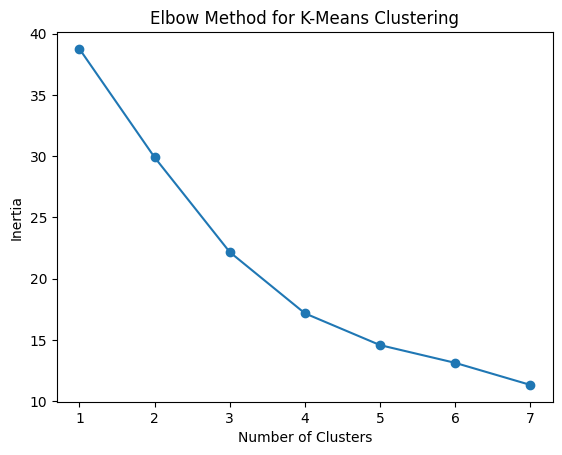

In [39]:
plt.plot(
    range(1, 8),
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means Clustering")

plt.show()

This is not immediately indicative of a clear k level. So we cross-check with other methods such as silhouette.

In [41]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 8):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42
    )

    cluster_labels = kmeans.fit_predict(cluster_scaled)

    score = silhouette_score(
        cluster_scaled,
        cluster_labels
    )

    silhouette_scores.append(score)

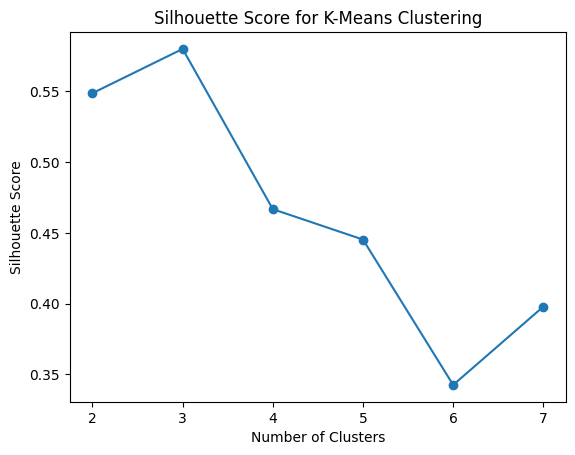

In [42]:
plt.plot(
    range(2, 8),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for K-Means Clustering")

plt.show()

The elbow method did not identify an unambiguous number of clusters. Therefore, the silhouette score was also calculated for solutions containing between 2 and 7 clusters. The highest silhouette score is obtained with three clusters (approximately 0.58), indicating that the three-cluster solution provides the strongest separation between municipalities among the alternatives considered. Therefore, K = 3 is selected for the final K-Means model.

Now that we have chosen K = 3, the next step is to actually fit the model, attach cluster labels to municipalities and then plot the clusters to see how it went graphically.

In [44]:
# Final K-Means model with 3 clusters

kmeans = KMeans(
    n_clusters=3,
    random_state=42
)

kmeans.fit(cluster_scaled)

# Add cluster assignment to the municipality dataset
municipality_clusters["CLUSTER"] = kmeans.labels_

municipality_clusters.head()

,MUNICIPALITY,ACCIDENTS,KILLED,ACCIDENTS_PER_CAPITA,ACCIDENTS_PER_KM2,FATALITIES_PER_ACCIDENT,CLUSTER
0,Abano Terme,236.0,3.0,0.002327,2.204773,0.012712,1
2,Abbadia Lariana,128.0,2.0,0.008031,1.540793,0.015625,0
3,Abbadia San Salvatore,29.0,1.0,0.000954,0.098316,0.034483,1
4,Abbasanta,16.0,0.0,0.001241,0.080308,0.000000,1
5,Abbateggio,2.0,0.0,0.001104,0.025972,0.000000,1


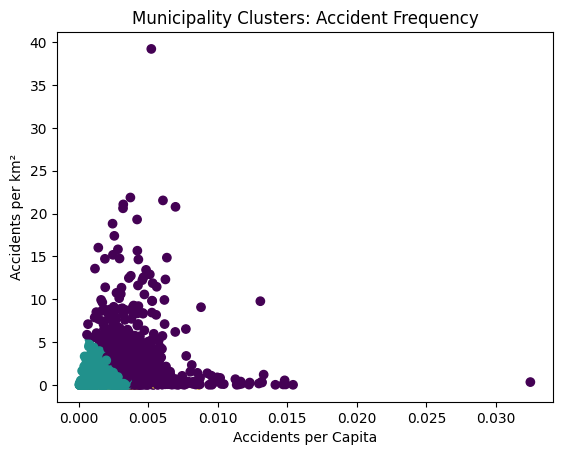

In [45]:
# start the plot with the original, unscaled variables
plt.scatter(
    municipality_clusters["ACCIDENTS_PER_CAPITA"],
    municipality_clusters["ACCIDENTS_PER_KM2"],
    c=municipality_clusters["CLUSTER"]
)

plt.xlabel("Accidents per Capita")
plt.ylabel("Accidents per km²")
plt.title("Municipality Clusters: Accident Frequency")

plt.show()


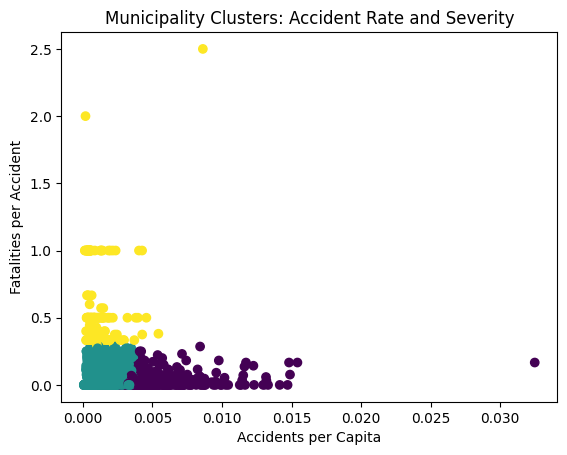

In [46]:
plt.scatter(
    municipality_clusters["ACCIDENTS_PER_CAPITA"],
    municipality_clusters["FATALITIES_PER_ACCIDENT"],
    c=municipality_clusters["CLUSTER"]
)

plt.xlabel("Accidents per Capita")
plt.ylabel("Fatalities per Accident")
plt.title("Municipality Clusters: Accident Rate and Severity")

plt.show()

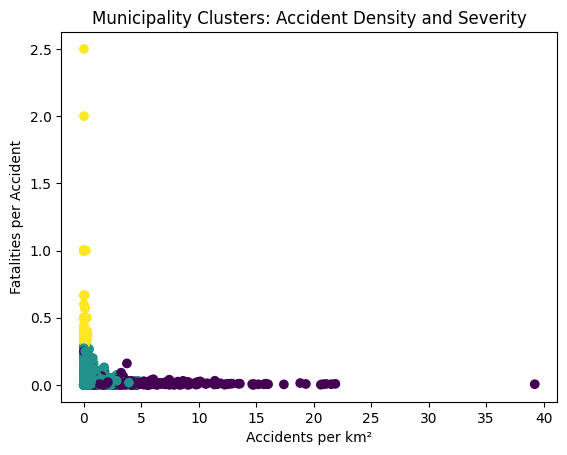

In [47]:
plt.scatter(
    municipality_clusters["ACCIDENTS_PER_KM2"],
    municipality_clusters["FATALITIES_PER_ACCIDENT"],
    c=municipality_clusters["CLUSTER"]
)

plt.xlabel("Accidents per km²")
plt.ylabel("Fatalities per Accident")
plt.title("Municipality Clusters: Accident Density and Severity")

plt.show()

In [49]:
# Get the mean of all the clustering variables per group
cluster_summary = municipality_clusters.groupby("CLUSTER")[
    ["ACCIDENTS_PER_CAPITA",
     "ACCIDENTS_PER_KM2",
     "FATALITIES_PER_ACCIDENT"]
].mean()

print(cluster_summary)

# Check value counts
print(municipality_clusters["CLUSTER"].value_counts())

# Check the underlying accident counts
municipality_clusters.groupby("CLUSTER")[
    ["ACCIDENTS", "KILLED"]
].mean()

         ACCIDENTS_PER_CAPITA  ACCIDENTS_PER_KM2  FATALITIES_PER_ACCIDENT
CLUSTER                                                                  
0                    0.004306           2.574632                 0.024990
1                    0.001480           0.344914                 0.032074
2                    0.001142           0.044124                 0.556076
CLUSTER
1    6337
0     917
2     181
Name: count, dtype: int64


,ACCIDENTS,KILLED
CLUSTER,,
0,538.719738,6.537623
1,44.380464,1.294619
2,3.701657,1.651934


**Cluster interpretation**

The three-cluster solution identifies three distinct accident profiles among Italian municipalities.

**Cluster 0** (917 municipalities) represents municipalities with relatively high accident frequency. It has the highest average accidents per capita and accidents per km², while fatalities per accident remain relatively low.

**Cluster 1** (6,337 municipalities) represents the most common profile. These municipalities have comparatively low accident frequency, accident density and fatalities per accident.

**Cluster 2** (181 municipalities) represents municipalities with low accident frequency but high measured severity. These municipalities average only 3.7 accidents over the period, but have a substantially higher fatalities-per-accident ratio. This result should be interpreted cautiously, as the severity indicator becomes sensitive to individual fatal accidents when the total number of accidents is very small.

Overall, the clustering suggests that municipalities differ not only in how frequently accidents occur, but also in the relationship between accident frequency and severity.

### Robustness check

As a check, I exclude municipalities that have very few accidents and re-run the clustering analysis.

In [51]:
# Robustness check: exclude municipalities with fewer than 5 accidents
municipality_robust = municipality_clusters[
    municipality_clusters["ACCIDENTS"] >= 5
].copy()

print("Original sample:", len(municipality_clusters))
print("Robustness sample:", len(municipality_robust))

Original sample: 7435
Robustness sample: 5977


In [52]:
robust_variables = municipality_robust[
    ["ACCIDENTS_PER_CAPITA",
     "ACCIDENTS_PER_KM2",
     "FATALITIES_PER_ACCIDENT"]
]
robust_variables.isna().sum()

ACCIDENTS_PER_CAPITA       0
ACCIDENTS_PER_KM2          0
FATALITIES_PER_ACCIDENT    0
dtype: int64

In [53]:
robust_scaler = MinMaxScaler()

robust_scaled = robust_scaler.fit_transform(robust_variables)

robust_scaled = pd.DataFrame(
    robust_scaled,
    columns=robust_variables.columns
)

In [54]:
kmeans_robust = KMeans(
    n_clusters=3,
    random_state=42
)

municipality_robust["CLUSTER"] = kmeans_robust.fit_predict(
    robust_scaled
)

In [55]:
robust_summary = municipality_robust.groupby("CLUSTER")[
    ["ACCIDENTS_PER_CAPITA",
     "ACCIDENTS_PER_KM2",
     "FATALITIES_PER_ACCIDENT"]
].mean()

print(robust_summary)

print(municipality_robust["CLUSTER"].value_counts())

         ACCIDENTS_PER_CAPITA  ACCIDENTS_PER_KM2  FATALITIES_PER_ACCIDENT
CLUSTER                                                                  
0                    0.001657           0.096461                 0.302253
1                    0.002099           0.897316                 0.015117
2                    0.001772           0.216702                 0.109606
CLUSTER
1    4714
2    1149
0     114
Name: count, dtype: int64


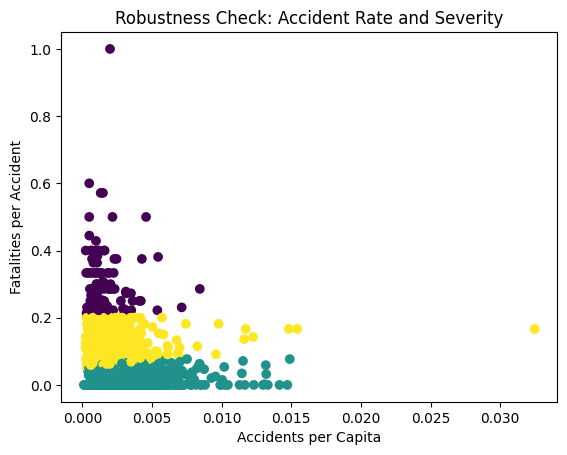

In [56]:
plt.scatter(
    municipality_robust["ACCIDENTS_PER_CAPITA"],
    municipality_robust["FATALITIES_PER_ACCIDENT"],
    c=municipality_robust["CLUSTER"]
)

plt.xlabel("Accidents per Capita")
plt.ylabel("Fatalities per Accident")
plt.title("Robustness Check: Accident Rate and Severity")

plt.show()

**Robustness check**
The severity indicator can produce extreme values for municipalities with very few accidents. For example, a municipality with one fatal accident out of one total accident would have a fatalities-per-accident rate of 1. To test whether these observations were driving the clustering results, the K-Means analysis was repeated after excluding municipalities with fewer than five accidents during the period.
The resulting clusters retain a similar broad structure, distinguishing a large group characterised by relatively low accident severity, an intermediate group, and a smaller high-severity group. However, the average fatalities-per-accident value of the highest-severity cluster falls substantially compared with the original analysis. This suggests that low-accident municipalities contributed to the extreme severity values observed in the original clustering, while the broader distinction between municipality profiles remains present.


## Overall Business Conclusion

The analysis identifies **two particularly important investment priorities**.

First, **large and densely populated urban areas — particularly Rome in terms of total accidents and Milan in terms of accident density — represent the strongest candidates for interventions aimed at reducing the overall number of road accidents**. Investment in these locations has the potential to address a large and geographically concentrated accident burden.

Second, the analysis identifies a smaller set of municipalities where **accident severity rather than accident frequency is the primary concern**. These municipalities may require a different type of intervention focused specifically on preventing fatal outcomes.

The central business insight is therefore that road-safety investment should distinguish between **high-frequency locations**, where the objective is to reduce a large volume of accidents, and **high-severity locations**, where fewer accidents occur but their consequences are considerably more serious.

Based on the observed data, **Rome and Milan emerge as particularly important locations for large-scale road-safety investment**, while the high-severity municipality cluster represents a second, distinct target for more specialised risk-reduction measures.

In [57]:
# Save final data for clarity.
df_final.to_csv("../data/df_final.csv", index=False)
municipality_clusters.to_csv("../data/municipality_clusters.csv", index=False)